# Avance 2 · Buscador de fotos en español

**Aprendizaje Automático III · Parcial II · Grupo A7**
**Equipo:** 
**Integrantes:** Emilio Frausto Ortiz, Juan, Rodrigo Rosales

Nuestro aplicativo guarda las fotos en el dispositivo. La idea es que el usuario escriba una frase, por ejemplo "perro en la playa", y le salgan las fotos más parecidas sin que nada se suba a internet.

## Cómo funciona

```
FOTO ─► TinyCLIP (no se entrena) ─► vector de 512 ─┐
                                                   ├─► se comparan ─► fotos más parecidas
FRASE ─► ALBETO (lo entrenamos) ─► vector de 512 ──┘

vectores de fotos ─► agrupar parecidas ─► nombrar grupo ─► el vector promedio queda con nombre
```

## Por qué lo hicimos así

- **Por qué ya no usamos YOLO:** antes detectábamos caras, pero ahora queremos buscar lugares y objetos con frases libres. YOLO solo reconoce las clases que aprendió y no da un vector que se pueda comparar con una frase. Por eso TinyCLIP tomó su lugar como módulo de visión.
- **Por qué TinyCLIP:** conecta imágenes y texto en los mismos vectores, y es una versión reducida de CLIP. Lo necesitamos ligero porque debe correr en dispositivos de todas las gamas.
- **Por qué entrenamos ALBETO:** TinyCLIP solo entiende inglés y nosotros queremos buscar en español. ALBETO es un modelo ligero de la familia BETO, y lo ajustamos para que una frase en español caiga en el mismo lugar que su versión en inglés.
- **Por qué dos tamaños:** la ligera pesa menos y la mediana busca mejor. Las probamos para escoger con datos.

## Con qué comparamos

- **Línea base:** TinyCLIP sin ajustar, recibiendo las frases en español.
- **Referencia:** TinyCLIP con las frases en inglés. Es lo mejor que podríamos alcanzar.

## Dónde está cada cosa

| Tema | Sección |
|---|---|
| Datos | 1 |
| Modelos | 2 |
| Entrenamiento y curvas | 3 |
| Línea base contra modelo propio | 4 |
| Errores y sesgos | 5 |
| Peso, velocidad y ONNX | 6 y 7 |
| Búsqueda con prompts | 8 |
| Agrupar y nombrar | 9 |
| Muchas fotos · Demostración | 10 · 11 |
| Conclusiones | 12 |
| Riesgos, siguientes pasos y referencias | 13 |


## 0. Configuración

Aquí escogemos qué modelo entrenar con `ENTRENAR`: `["ligera"]`, `["mediana"]` o los dos.

In [1]:
# Si falta algo: ml3\Scripts\python.exe -m pip install onnx onnxruntime onnxscript sacremoses sentencepiece
import os, ast, json, math, time, random, re, shutil, warnings
from pathlib import Path
from collections import Counter

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer
from transformers import AutoModel, AutoTokenizer, AutoModelForSeq2SeqLM, CLIPModel
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
warnings.filterwarnings("ignore")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

FAST = os.environ.get("AVANCE2_FAST", "0") == "1"
SEED = 42
ROOT = Path.cwd()
CACHE = Path.home() / ".cache" / "avance2"      # datos pesados, fuera de OneDrive
OUT = ROOT / "salidas_avance2"
CACHE.mkdir(parents=True, exist_ok=True); OUT.mkdir(exist_ok=True)

# Las dos opciones para que Juan elija
VARIANTS = {
    "ligera":  dict(clip="wkcn/TinyCLIP-ViT-8M-16-Text-3M-YFCC15M",   texto="dccuchile/albert-tiny-spanish"),
    "mediana": dict(clip="wkcn/TinyCLIP-ViT-39M-16-Text-19M-YFCC15M", texto="dccuchile/albert-base-spanish"),
}
# Cuál entrenar. La que quiten usa sus pesos ya guardados, para seguir comparando las dos.
# Tiempo en la RTX 4050: ligera ~6 min, mediana ~1 hora.
ENTRENAR = ["ligera", "mediana"]

CFG = dict(caps_por_imagen=2, n_palabras=3000, rep_palabras=5, max_len=32,
           epochs=6, batch=256, lr_enc=1e-4, lr_head=1e-3, wd=0.01, tau=0.05)
N_IMGS, N_VAL = None, 5000
if FAST:
    CFG.update(epochs=1, n_palabras=300); N_IMGS, N_VAL = 2000, 300

def seed_all():
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
seed_all()
DEV = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.float_format", "{:.3f}".format)
print("FAST:", FAST, "|", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "")

W1105 15:56:47.213000 9356 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


FAST: False | cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Datos

| Conjunto | Para qué lo usamos | Tamaño | Etiquetas |
|---|---|---|---|
| **COCO Captions** (solo texto) | Entrenar | ~113 mil fotos, 2 frases de cada una | Inglés de personas, español **traducido a máquina** |
| Palabras frecuentes de COCO | Entrenar búsquedas cortas ("playa") | 3 000 | Igual |
| **COCO validación** | Elegir el mejor modelo | 5 000 frases | Igual |
| **XM3600** | **Prueba con datos no vistos** | 3 600 fotos de 36 regiones | Español **escrito por personas** |

- **Por qué COCO:** tiene muchas frases que describen objetos y lugares de la vida diaria, justo lo que un usuario buscaría.
- **Por qué no bajamos sus imágenes:** el entrenamiento compara texto contra texto, así que nos ahorramos muchos GB.
- **Por qué XM3600:** sus frases en español las escribieron personas y sus fotos vienen de muchas regiones. Así probamos con algo distinto a lo que vio el modelo.

### 1.1 Frases de COCO
Usamos 2 frases por imagen y sacamos las palabras más frecuentes, para que también funcionen búsquedas de una sola palabra.

In [2]:
def read_coco(split):
    f = hf_hub_download("yerevann/coco-karpathy", f"data/{split}-00000-of-00001.parquet", repo_type="dataset")
    s = pq.read_table(f, columns=["sentences"]).to_pydict()["sentences"]
    return [ast.literal_eval(x) if isinstance(x, str) else x for x in s]

rng = np.random.default_rng(SEED)
imgs = read_coco("train") + read_coco("restval")
if N_IMGS: imgs = [imgs[i] for i in rng.choice(len(imgs), N_IMGS, replace=False)]
en_train = [c.strip() for caps in imgs for c in list(rng.permutation(caps))[:CFG["caps_por_imagen"]]]
en_val = [c[0].strip() for c in read_coco("validation")][:N_VAL]

# Palabras frecuentes, para que también funcionen búsquedas de una palabra
STOP = set("a an the of on in at with and to is are was were it its his her their there this that for by from as two three some very next near while who has have top up down over one".split())
freq = Counter(w for c in en_train for w in re.findall(r"[a-z]{3,}", c.lower()) if w not in STOP)
en_words = [w for w, _ in freq.most_common(CFG["n_palabras"])]
print(len(en_train), "frases |", len(en_val), "validación |", len(en_words), "palabras |", en_train[:2], en_words[:8])

226574 frases | 5000 validación | 3000 palabras | ['A table is adorned with wooden chairs with blue accents.', 'a long table with a plant on top of it surrounded with wooden chairs'] ['man', 'sitting', 'standing', 'people', 'white', 'woman', 'street', 'table']


### 1.2 Traducción al español (datos sintéticos)
COCO viene en inglés, así que traducimos las frases con OPUS-MT. Por eso decimos que son datos sintéticos.

In [3]:
def translate(texts, bs=256):
    tk = AutoTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-es")
    mt = AutoModelForSeq2SeqLM.from_pretrained("Helsinki-NLP/opus-mt-en-es").to(DEV).eval()
    if DEV == "cuda": mt = mt.half()
    mt.generation_config.max_length = None
    order = np.argsort([len(t) for t in texts]); out = [None] * len(texts)   # por longitud: menos relleno
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        with torch.no_grad():
            o = mt.generate(**tk([texts[j] for j in idx], return_tensors="pt", padding=True).to(DEV), max_new_tokens=48, num_beams=1)
        for j, t in zip(idx, tk.batch_decode(o, skip_special_tokens=True)): out[j] = t
    del mt; torch.cuda.empty_cache()
    return out

tr_file = CACHE / f"traducciones{'_fast' if FAST else ''}.json"
if tr_file.exists():
    tr = json.load(open(tr_file, encoding="utf8"))
else:
    t0 = time.time()
    tr = dict(train=translate(en_train), val=translate(en_val), words=translate(en_words))
    json.dump(tr, open(tr_file, "w", encoding="utf8"), ensure_ascii=False)
    print(f"traducido en {(time.time()-t0)/60:.1f} min")
es_train, es_val, es_words = tr["train"], tr["val"], tr["words"]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

traducido en 14.3 min


### 1.3 Revisión a mano
Como la traducción es automática, revisamos una muestra para ver qué tan buena es.

**Errores que encontramos:** [COMPLETAR DESPUÉS DE REVISAR LA TABLA]

In [4]:
r = np.random.default_rng(1)
rev = pd.DataFrame({"inglés": [en_train[i] for i in r.choice(len(en_train), 12)] + [en_words[i] for i in r.choice(len(en_words), 12)]})
rev["español"] = [es_train[en_train.index(t)] for t in rev["inglés"][:12]] + [es_words[en_words.index(t)] for t in rev["inglés"][12:]]
rev.to_csv(OUT / "revision_traducciones.csv", index=False)
with pd.option_context("display.max_colwidth", 80): display(rev)

,inglés,español
0,A yellow and silver train traveling down train tracks.,Un tren amarillo y plateado que viaja por las vías del tren.
1,A man on a skateboard in a city square,Un hombre en una patineta en una plaza de la ciudad
2,A bald man with a goatee cuts a bundt cake.,Un calvo con barba corta un pastel.
3,A traffic pole with numerous signs attached to it.,Un poste de tráfico con numerosas señales adheridas a él.
4,A young boy posing with a tennis racket.,Un chico joven posando con una raqueta de tenis.
5,A tall clock tower with a clock on each of it's sides.,Una torre de reloj alto con un reloj en cada uno de sus lados.
6,Giraffes and zebras are within the same enclosure.,Las jirafas y las cebras están dentro del mismo recinto.
7,A modern day bathroom with a unusual sink,Un moderno baño con un lavabo inusual
8,An old broken skateboard laying on the beach.,Un viejo monopatín roto en la playa.
9,A zebra eats grass near a wire fence.,Una cebra come hierba cerca de una cerca de alambre.


### 1.4 XM3600: fotos y frases en español para la prueba
Estas fotos no se usan para entrenar, solo para medir el resultado final.

,conjunto,cantidad,unidad
0,COCO entrenamiento,226574,frases
1,Palabras,3000,palabras
2,COCO validación,5000,frases
3,XM3600 prueba,3600,fotos
4,XM3600 prueba,8614,frases en español
5,XM3600 regiones,36,regiones


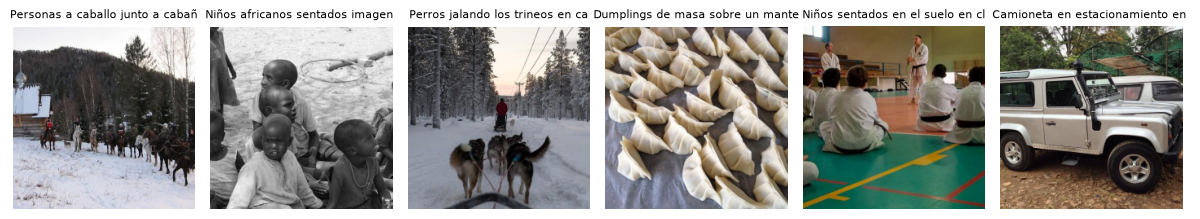

In [5]:
def center_crop(b, s=224):
    im = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_COLOR)[:, :, ::-1]
    h, w = im.shape[:2]; k = s / min(h, w)
    im = cv2.resize(im, (round(w * k), round(h * k)), interpolation=cv2.INTER_AREA if k < 1 else cv2.INTER_CUBIC)
    h, w = im.shape[:2]; y, x = (h - s) // 2, (w - s) // 2
    return im[y:y + s, x:x + s]

xm_file = CACHE / "xm3600_es.npz"
if xm_file.exists():
    z = np.load(xm_file, allow_pickle=True); G, G_loc, G_id, q_es, q_es_img, q_en, q_en_img = [z[k] for k in ["G", "loc", "id", "q_es", "q_es_img", "q_en", "q_en_img"]]
else:
    f = hf_hub_download("floschne/xm3600", "data/es-00000-of-00001.parquet", repo_type="dataset")
    fe = hf_hub_download("floschne/xm3600", "data/en-00000-of-00001.parquet", repo_type="dataset")
    Gs, G_loc, G_id, q_es, q_es_img = [], [], [], [], []
    for b in pq.ParquetFile(f).iter_batches(batch_size=64):
        d = b.to_pydict()
        for im, loc, i, caps in zip(d["image"], d["image_locale"], d["image_id"], d["captions"]):
            k = len(Gs); Gs.append(center_crop(im["bytes"])); G_loc.append(loc); G_id.append(i)
            q_es += caps; q_es_img += [k] * len(caps)
    pos = {i: k for k, i in enumerate(G_id)}
    t = pq.read_table(fe, columns=["image_id", "captions"]).to_pydict(); q_en, q_en_img = [], []
    for i, caps in zip(t["image_id"], t["captions"]): q_en += caps; q_en_img += [pos[i]] * len(caps)
    G, G_loc, G_id = np.stack(Gs), np.array(G_loc), np.array(G_id)
    q_es, q_es_img, q_en, q_en_img = np.array(q_es), np.array(q_es_img), np.array(q_en), np.array(q_en_img)
    np.savez(xm_file, G=G, loc=G_loc, id=G_id, q_es=q_es, q_es_img=q_es_img, q_en=q_en, q_en_img=q_en_img)
if FAST:
    keep = np.arange(600); G, G_loc = G[keep], G_loc[keep]
    m = q_es_img < 600; q_es, q_es_img = q_es[m], q_es_img[m]
    m = q_en_img < 600; q_en, q_en_img = q_en[m], q_en_img[m]
q_es, q_en = [str(x) for x in q_es], [str(x) for x in q_en]

stats = pd.DataFrame([["COCO entrenamiento", len(en_train), "frases"], ["Palabras", len(en_words), "palabras"],
                      ["COCO validación", len(en_val), "frases"], ["XM3600 prueba", len(G), "fotos"],
                      ["XM3600 prueba", len(q_es), "frases en español"], ["XM3600 regiones", len(set(G_loc)), "regiones"]],
                     columns=["conjunto", "cantidad", "unidad"])
stats.to_csv(OUT / "tabla_datos.csv", index=False); display(stats)

def grid(imgs, titles=None, ncol=6, size=2.0, path=None):
    nrow = math.ceil(len(imgs) / ncol)
    fig, axs = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size * 1.15))
    for k, a in enumerate(np.array(axs).reshape(-1)):
        a.axis("off")
        if k < len(imgs):
            a.imshow(imgs[k])
            if titles: a.set_title(titles[k], fontsize=8)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=110)
    plt.show()

i = np.random.default_rng(2).choice(len(q_es), 6)
grid([G[q_es_img[j]] for j in i], [q_es[j][:32] for j in i], path=OUT / "fig_muestras_xm3600.png")

## 2. Modelos

- **Imagen:** TinyCLIP, sin cambios. Es preentrenado, así que no es la parte que entrenamos.
- **Texto (lo que ajustamos):** ALBETO lee la frase, promediamos sus tokens y una capa lineal lo convierte en un vector de 512, igual que el de las fotos.

In [6]:
class ImageEncoder(nn.Module):
    # Entrada: [N,3,224,224] RGB 0-1. La normalización va dentro para que el aplicativo no la repita.
    def __init__(self, clip):
        super().__init__()
        self.vision, self.proj = clip.vision_model, clip.visual_projection
        self.register_buffer("mean", torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1))
    def forward(self, x):
        return F.normalize(self.proj(self.vision(pixel_values=(x - self.mean) / self.std).pooler_output), dim=1)

class TextStudent(nn.Module):
    def __init__(self, hub, dim=512):
        super().__init__()
        self.enc = AutoModel.from_pretrained(hub, attn_implementation="eager")
        self.head = nn.Linear(self.enc.config.hidden_size, dim)
    def forward(self, input_ids, attention_mask):
        h = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        return F.normalize(self.head((h * m).sum(1) / m.sum(1).clamp(min=1)).float(), dim=1)

def load_tok(hub):
    # AutoTokenizer falla con ALBETO en transformers 5; tokenizer.json funciona y es lo que usará el aplicativo.
    t = Tokenizer.from_file(hf_hub_download(hub, "tokenizer.json"))
    t.enable_truncation(CFG["max_len"]); t.enable_padding(pad_id=0, pad_token="<pad>", length=CFG["max_len"])
    return t

def tokenize(tok, texts):
    e = tok.encode_batch(list(texts))
    return np.array([x.ids for x in e], np.int64), np.array([x.attention_mask for x in e], np.int64)

@torch.no_grad()
def clip_text(clip, tok, texts, bs=512):
    # Vectores de TinyCLIP para un texto (el "maestro")
    out = []
    for i in range(0, len(texts), bs):
        b = tok(list(texts[i:i + bs]), padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEV)
        o = clip.text_model(input_ids=b.input_ids, attention_mask=b.attention_mask).pooler_output
        out.append(F.normalize(clip.text_projection(o), dim=1).float().cpu())
    return torch.cat(out)

@torch.no_grad()
def student_text(model, tok, texts, bs=512):
    model.eval(); ids, am = tokenize(tok, texts); out = []
    for i in range(0, len(ids), bs):
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            out.append(model(torch.from_numpy(ids[i:i + bs]).to(DEV), torch.from_numpy(am[i:i + bs]).to(DEV)).float().cpu())
    return torch.cat(out)

@torch.no_grad()
def image_vecs(enc, X, bs=128):
    enc.eval(); out = []
    for i in range(0, len(X), bs):
        x = torch.from_numpy(np.ascontiguousarray(X[i:i + bs])).to(DEV).permute(0, 3, 1, 2).float().div_(255)
        out.append(enc(x).float().cpu())
    return torch.cat(out).numpy()

t = load_tok(VARIANTS["ligera"]["texto"])
print(t.encode("Un niño corriendo en la playa al atardecer").tokens)

['[CLS]', '▁un', '▁niño', '▁corriendo', '▁en', '▁la', '▁playa', '▁al', '▁atardecer', '[SEP]', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


## 3. Entrenamiento

- **Entrada:** una frase en español.
- **Lo que debe sacar:** el vector que TinyCLIP da a esa frase en inglés.
- **Pérdida:** tiene dos partes. El coseno acerca cada frase a su vector correcto. InfoNCE la aleja de los vectores de las otras frases del lote, para que no todas queden en el mismo lugar.
- **Optimizador:** AdamW. Al inicio el *learning rate* sube poco a poco (*warmup*) y luego baja suave (*cosine decay*), para que el modelo no olvide lo que ya sabía.
- **Modelo final:** nos quedamos con la época que tuvo mejor coseno en validación.

### ¿Cuándo se entrena la parte de imágenes y cuándo BETO?

**La parte de imágenes nunca se entrena. Solo se entrena BETO** (usamos ALBETO, un modelo ligero de la familia BETO).

TinyCLIP ya sabe ver fotos y convertirlas en vectores, pero solo entiende inglés. Si le escribimos en español, busca mal. Por eso no tocamos cómo ve las fotos: le enseñamos a BETO a "hablar" en los mismos vectores.

Le damos a BETO una frase en español y le pedimos que saque el mismo vector que TinyCLIP saca con esa frase en inglés. Así, "perro en la playa" cae cerca de las fotos de perros y playas.

| | Imagen (TinyCLIP) | Texto (BETO) |
|---|---|---|
| ¿Se entrena? | No, se usa tal cual | Sí, en esta sección |
| ¿Qué recibe? | Una foto | Una frase en español |
| ¿Cuándo se usa en el aplicativo? | Una vez por cada foto nueva | Cada vez que alguien busca |

- **En el entrenamiento no entra ninguna foto**, solo frases. Las fotos entran hasta la evaluación.
- **El entrenamiento se hace una vez**, aquí, y luego se exporta. El aplicativo ya no entrena.
- **Si agregamos fotos**, no se reentrena nada: solo se calcula el vector de cada foto nueva.
- **Si reentrenamos BETO**, los vectores de las fotos siguen sirviendo, porque TinyCLIP no cambió.
- **Si cambiamos TinyCLIP** o pasamos de ligera a mediana, hay que recalcular los vectores de todas las fotos.

In [7]:
print(pd.Series(CFG).to_frame("hiperparámetro").T.to_string())

def train_variant(name, v):
    seed_all()
    clip = CLIPModel.from_pretrained(v["clip"]).to(DEV).eval()
    ctok = AutoTokenizer.from_pretrained(v["clip"])
    prompts = [f"a photo of {w}" for w in en_words]
    tgt = torch.cat([clip_text(clip, ctok, en_train)] + [clip_text(clip, ctok, prompts)] * CFG["rep_palabras"])
    tgt_val = clip_text(clip, ctok, en_val).to(DEV)
    del clip; torch.cuda.empty_cache()

    tok = load_tok(v["texto"])
    ids, am = tokenize(tok, list(es_train) + list(es_words) * CFG["rep_palabras"])
    model = TextStudent(v["texto"]).to(DEV)
    opt = torch.optim.AdamW([{"params": model.enc.parameters(), "lr": CFG["lr_enc"]},
                             {"params": model.head.parameters(), "lr": CFG["lr_head"]}], weight_decay=CFG["wd"])
    steps = len(ids) // CFG["batch"]; total = steps * CFG["epochs"]; warm = max(1, int(.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else .5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler(enabled=DEV == "cuda")
    hist, best, ckpt = [], -1, OUT / f"{name}_texto.pt"

    for ep in range(CFG["epochs"]):
        model.train(); t0 = time.time(); perm = np.random.permutation(len(ids)); tot = 0
        for s in range(steps):
            i = perm[s * CFG["batch"]:(s + 1) * CFG["batch"]]
            a, b, y = torch.from_numpy(ids[i]).to(DEV), torch.from_numpy(am[i]).to(DEV), tgt[i].to(DEV)
            with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
                e = model(a, b)
            loss = (1 - (e * y).sum(1)).mean() + F.cross_entropy(e @ y.T / CFG["tau"], torch.arange(len(i), device=DEV))
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        ev = student_text(model, tok, es_val).to(DEV)
        cos = (ev * tgt_val).sum(1).mean().item()
        r1 = ((ev @ tgt_val.T).argmax(1) == torch.arange(len(ev), device=DEV)).float().mean().item()
        hist.append(dict(epoca=ep + 1, loss=tot / steps, val_coseno=cos, val_R1=r1, seg=time.time() - t0))
        print(f"  [{name}] ep{ep+1}: loss {tot/steps:.3f}  val coseno {cos:.3f}  val R@1 {r1:.3f}  ({time.time()-t0:.0f}s)")
        if cos > best: best = cos; torch.save(model.state_dict(), ckpt)
    model.load_state_dict(torch.load(ckpt, map_location=DEV)); model.eval()
    return model, tok, pd.DataFrame(hist)

MODELS, TOKS, HIST = {}, {}, {}
for name, v in list(VARIANTS.items()):
    pesos, hist = OUT / f"{name}_texto.pt", OUT / f"historial_{name}.csv"
    if name in ENTRENAR:
        print("=== entrenando", name, "===")
        MODELS[name], TOKS[name], HIST[name] = train_variant(name, v)
        HIST[name].to_csv(hist, index=False)
    elif pesos.exists():
        print("=== usando pesos guardados de", name, "===")
        MODELS[name] = TextStudent(v["texto"]).to(DEV)
        MODELS[name].load_state_dict(torch.load(pesos, map_location=DEV)); MODELS[name].eval()
        TOKS[name] = load_tok(v["texto"])
        if hist.exists(): HIST[name] = pd.read_csv(hist)
    else:
        print("=== se omite", name, ": no está en ENTRENAR y no tiene pesos ===")
        del VARIANTS[name]
assert VARIANTS, "Pongan al menos un modelo en ENTRENAR"

                caps_por_imagen  n_palabras  rep_palabras  max_len  epochs   batch  lr_enc  lr_head    wd   tau
hiperparámetro            2.000    3000.000         5.000   32.000   6.000 256.000   0.000    0.001 0.010 0.050
=== ligera ===


Loading weights:   0%|          | 0/222 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertModel LOAD REPORT from: dccuchile/albert-tiny-spanish
Key                              | Status     |  | 
---------------------------------+------------+--+-
predictions.LayerNorm.weight     | UNEXPECTED |  | 
predictions.dense.weight         | UNEXPECTED |  | 
predictions.decoder.bias         | UNEXPECTED |  | 
sop_classifier.classifier.bias   | UNEXPECTED |  | 
predictions.decoder.weight       | UNEXPECTED |  | 
predictions.dense.bias           | UNEXPECTED |  | 
predictions.bias                 | UNEXPECTED |  | 
sop_classifier.classifier.weight | UNEXPECTED |  | 
predictions.LayerNorm.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [ligera] ep1: loss 1.243  val coseno 0.820  val R@1 0.900  (56s)


  [ligera] ep2: loss 0.448  val coseno 0.855  val R@1 0.938  (64s)


... (10 outputs left out)

  [mediana] ep3: loss 0.221  val coseno 0.908  val R@1 0.973  (578s)


  [mediana] ep4: loss 0.199  val coseno 0.916  val R@1 0.976  (574s)


  [mediana] ep5: loss 0.185  val coseno 0.920  val R@1 0.977  (582s)


  [mediana] ep6: loss 0.180  val coseno 0.921  val R@1 0.976  (561s)


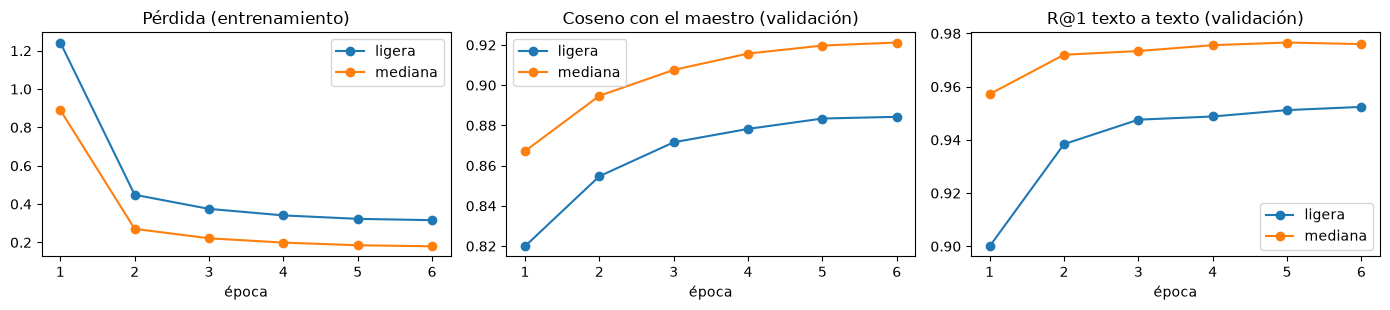

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for n, h in HIST.items():
    for a, c in zip(ax, ["loss", "val_coseno", "val_R1"]): a.plot(h.epoca, h[c], marker="o", label=n)
for a, t in zip(ax, ["Pérdida (entrenamiento)", "Coseno con el maestro (validación)", "R@1 texto a texto (validación)"]):
    a.set_title(t); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.savefig(OUT / "fig_curvas.png", dpi=120); plt.show()

## 4. Evaluación: línea base contra modelo propio

Probamos con XM3600, que el modelo no vio. Para cada frase ordenamos todas las fotos y vemos en qué lugar quedó la correcta.

- **R@K:** porcentaje de frases con la foto correcta entre las primeras K. R@10 es el que más nos importa, porque el usuario ve varias fotos a la vez.
- **MRR:** qué tan arriba queda la foto correcta. Entre más cerca de 1, mejor.
- **Mediana:** el lugar típico de la foto correcta. Entre más bajo, mejor.

Loading weights:   0%|          | 0/222 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/302 [00:00<?, ?it/s]

,variante,modelo,R1,R5,R10,MRR,mediana
0,ligera,"línea base (TinyCLIP, español)",0.086,0.218,0.289,0.155,46.000
1,ligera,"modelo propio (ALBETO, español)",0.238,0.495,0.612,0.361,6.000
2,ligera,"referencia (TinyCLIP, inglés)",0.360,0.648,0.752,0.493,3.000
3,mediana,"línea base (TinyCLIP, español)",0.219,0.432,0.533,0.324,8.000
4,mediana,"modelo propio (ALBETO, español)",0.385,0.657,0.758,0.511,2.000
5,mediana,"referencia (TinyCLIP, inglés)",0.494,0.767,0.844,0.618,2.000


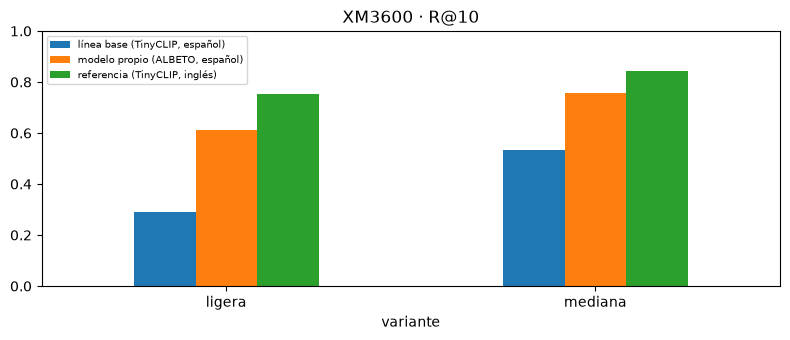

Mejor R@10: mediana


In [9]:
def retrieval(Q, Gv, target):
    S = Q @ Gv.T
    rank = (S > S[np.arange(len(Q)), target][:, None]).sum(1) + 1
    return dict(R1=(rank <= 1).mean(), R5=(rank <= 5).mean(), R10=(rank <= 10).mean(), MRR=(1 / rank).mean(), mediana=float(np.median(rank))), rank

rows, GV, RANKS = [], {}, {}
for name, v in VARIANTS.items():
    clip = CLIPModel.from_pretrained(v["clip"]).to(DEV).eval(); ctok = AutoTokenizer.from_pretrained(v["clip"])
    GV[name] = image_vecs(ImageEncoder(clip).to(DEV), G)
    for tipo, Q, tg in [("línea base (TinyCLIP, español)", clip_text(clip, ctok, q_es).numpy(), q_es_img),
                        ("modelo propio (ALBETO, español)", student_text(MODELS[name], TOKS[name], q_es).numpy(), q_es_img),
                        ("referencia (TinyCLIP, inglés)", clip_text(clip, ctok, q_en).numpy(), q_en_img)]:
        m, rk = retrieval(Q, GV[name], tg); rows.append(dict(variante=name, modelo=tipo, **m)); RANKS[(name, tipo)] = rk
    del clip; torch.cuda.empty_cache()
RES = pd.DataFrame(rows); RES.to_csv(OUT / "resultados_xm3600.csv", index=False); display(RES)

p = RES.pivot(index="variante", columns="modelo", values="R10")
p.plot.bar(rot=0, figsize=(8, 3.5), title="XM3600 · R@10"); plt.ylim(0, 1); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "fig_base_vs_propio.png", dpi=120); plt.show()
PROPIO = "modelo propio (ALBETO, español)"
BEST = RES[RES.modelo == PROPIO].set_index("variante").R10.idxmax(); print("Mejor R@10:", BEST)

## 5. Errores y sesgos
### 5.1 Frases donde falla
En cada fila, la primera foto es la correcta y las demás son las que devolvió el modelo.

«Dos jícamas sobre una mesa blanca» · la correcta quedó en el lugar 1209


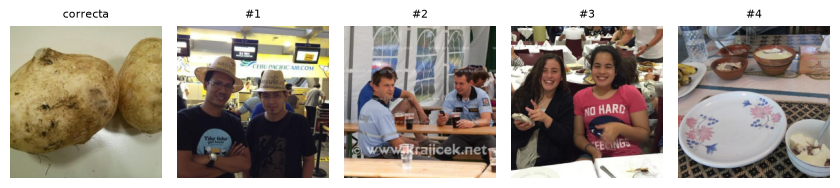

«Exterior del dolise romano visto de abajo hacia arriba.» · la correcta quedó en el lugar 1172


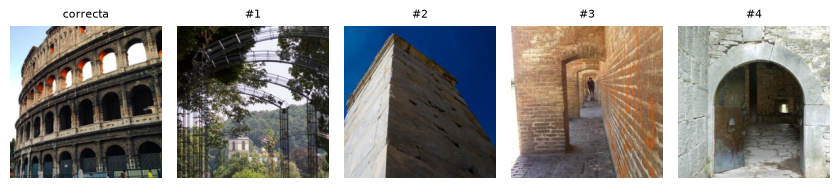

«Acercamiento de granadas.» · la correcta quedó en el lugar 1093


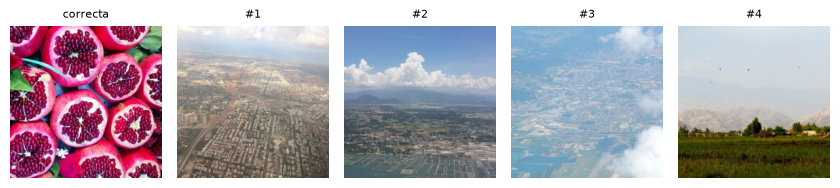

«Macaco de Berbería sentado sobre el suelo de piedra y tierra al pie de un árbol» · la correcta quedó en el lugar 918


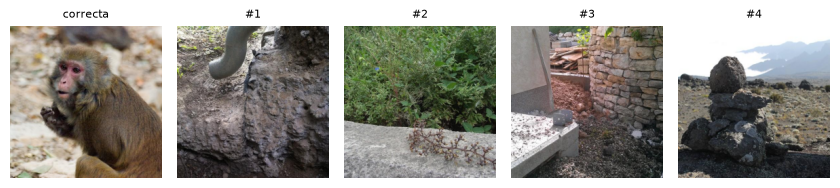

In [10]:
rk = RANKS[(BEST, PROPIO)]
Qb = student_text(MODELS[BEST], TOKS[BEST], q_es).numpy()
for j in np.argsort(-rk)[:4]:
    top = np.argsort(-(Qb[j] @ GV[BEST].T))[:4]
    print(f"«{q_es[j]}» · la correcta quedó en el lugar {rk[j]}")
    grid([G[q_es_img[j]]] + [G[t] for t in top], ["correcta"] + [f"#{k+1}" for k in range(4)], ncol=5, size=1.7)

**Qué vimos en estos errores:**

- **Palabras raras:** "jícamas" y "Macaco de Berbería" casi no aparecen en frases como las de COCO. En el caso del macaco, el modelo se fue con "suelo de piedra" y devolvió fotos de piedras.
- **Faltas de ortografía:** "dolise" parece ser "coliseo". El modelo no reconoce el lugar, aunque sí trae construcciones de piedra.
- **Palabras con varios sentidos o frases muy cortas:** en "Acercamiento de granadas" no encontró la fruta y devolvió paisajes.

Estos casos muestran que el modelo depende mucho de las palabras que vio al entrenar.

### 5.2 Por región de la foto
Medimos R@10 por región para ver si funciona mejor con fotos de ciertos lugares. Si hay diferencias grandes, puede haber sesgo: COCO tiene sobre todo escenas occidentales.

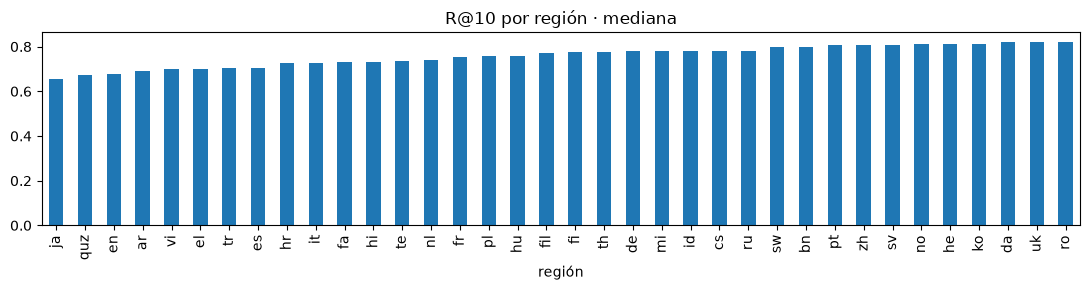

Peores: {'ja': 0.66, 'quz': 0.67, 'en': 0.68, 'ar': 0.69, 'vi': 0.7}
Mejores: {'he': 0.81, 'ko': 0.81, 'da': 0.82, 'uk': 0.82, 'ro': 0.82}


In [11]:
loc = G_loc[q_es_img]
B = pd.DataFrame({"región": loc, "propio": rk <= 10, "base": RANKS[(BEST, "línea base (TinyCLIP, español)")] <= 10}).groupby("región").mean().sort_values("propio")
B.to_csv(OUT / "resultados_region.csv"); B.propio.plot.bar(figsize=(11, 3), title=f"R@10 por región · {BEST}")
plt.tight_layout(); plt.savefig(OUT / "fig_region.png", dpi=120); plt.show()
print("Peores:", B.head(5).propio.round(2).to_dict()); print("Mejores:", B.tail(5).propio.round(2).to_dict())

## 6. Exportar a ONNX

Exportamos a ONNX para que el aplicativo pueda usar los modelos sin instalar PyTorch. También los pasamos a int8, que guarda los pesos con menos precisión para que ocupen menos.

| Archivo | Entrada | Salida |
|---|---|---|
| `<variante>_imagen_*.onnx` | `imagen` `[N,3,224,224]` float32, RGB 0–1 | `vector` `[N,512]` normalizado |
| `<variante>_texto_*.onnx` | `input_ids`, `attention_mask` `[N,L]` int64 | `vector` `[N,512]` normalizado |

Para comparar una frase con una foto usamos el producto punto. Si cambia el modelo de imagen, hay que recalcular los vectores guardados.

In [12]:
import logging; logging.getLogger().setLevel(logging.ERROR)
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic, QuantType

def quant(a, b):   # solo capas lineales: cuantizar convoluciones daña el vector
    quantize_dynamic(str(a), str(b), weight_type=QuantType.QInt8, op_types_to_quantize=["MatMul", "Gemm"])

def sess(p, threads=None):
    so = ort.SessionOptions()
    if threads: so.intra_op_num_threads = threads
    return ort.InferenceSession(str(p), so, providers=["CPUExecutionProvider"])

def ort_image(s, X, bs=32):
    return np.concatenate([s.run(None, {"imagen": X[i:i + bs].transpose(0, 3, 1, 2).astype(np.float32) / 255})[0] for i in range(0, len(X), bs)])

def ort_text(s, tok, texts, bs=256):
    ids, am = tokenize(tok, texts)
    return np.concatenate([s.run(None, {"input_ids": ids[i:i + bs], "attention_mask": am[i:i + bs]})[0] for i in range(0, len(ids), bs)])

def ms(f, n=30):
    for _ in range(5): f()
    t = []
    for _ in range(n): a = time.perf_counter(); f(); t.append(time.perf_counter() - a)
    return 1000 * float(np.median(t))

rows = []
for name, v in VARIANTS.items():
    clip = CLIPModel.from_pretrained(v["clip"]).eval()
    img = ImageEncoder(clip).eval(); txt = MODELS[name].cpu().eval()
    pi, pi8 = OUT / f"{name}_imagen_fp32.onnx", OUT / f"{name}_imagen_int8.onnx"
    pt, pt8 = OUT / f"{name}_texto_fp32.onnx", OUT / f"{name}_texto_int8.onnx"
    torch.onnx.export(img, torch.rand(2, 3, 224, 224), str(pi), input_names=["imagen"], output_names=["vector"],
                      dynamic_axes={"imagen": {0: "n"}, "vector": {0: "n"}}, opset_version=17, dynamo=False)
    a = torch.ones(2, CFG["max_len"], dtype=torch.long)
    torch.onnx.export(txt, (a, a), str(pt), input_names=["input_ids", "attention_mask"], output_names=["vector"],
                      dynamic_axes={"input_ids": {0: "n", 1: "l"}, "attention_mask": {0: "n", 1: "l"}, "vector": {0: "n"}}, opset_version=17, dynamo=False)
    quant(pi, pi8); quant(pt, pt8)
    MODELS[name].to(DEV)
    ref_t = student_text(MODELS[name], TOKS[name], q_es).numpy()
    r = dict(variante=name)
    for tag, a, b in [("fp32", pi, pt), ("int8", pi8, pt8)]:
        si, st = sess(a), sess(b)
        Gv, Q = ort_image(si, G), ort_text(st, TOKS[name], q_es)
        r[f"MB_{tag}"] = (a.stat().st_size + b.stat().st_size) / 1e6
        r[f"MB_imagen_{tag}"] = a.stat().st_size / 1e6; r[f"MB_texto_{tag}"] = b.stat().st_size / 1e6
        r[f"coseno_imagen_{tag}"] = float((Gv * GV[name]).sum(1).mean()); r[f"coseno_texto_{tag}"] = float((Q * ref_t).sum(1).mean())
        r[f"R10_{tag}"] = retrieval(Q, Gv, q_es_img)[0]["R10"]
        s1, s2 = sess(a, 1), sess(b, 1); x = np.random.rand(1, 3, 224, 224).astype(np.float32); ii, aa = tokenize(TOKS[name], ["un perro en la playa"])
        r[f"ms_foto_{tag}"] = ms(lambda: s1.run(None, {"imagen": x})); r[f"ms_frase_{tag}"] = ms(lambda: s2.run(None, {"input_ids": ii, "attention_mask": aa}))
        if tag == "int8": np.save(OUT / f"{name}_vectores_xm3600.npy", Gv)
    rows.append(r)
    shutil.copy(hf_hub_download(v["texto"], "tokenizer.json"), OUT / f"{name}_tokenizer.json")
    json.dump(dict(version=f"{name}-v1-{time.strftime('%Y%m%d')}", imagen=v["clip"], texto=v["texto"], dim=512, max_len=CFG["max_len"],
                   imagen_entrada="[N,3,224,224] float32 RGB 0-1, lado corto a 224 y recorte central", similitud="producto punto"),
              open(OUT / f"{name}_meta.json", "w"), indent=2, ensure_ascii=False)
EXPORT = pd.DataFrame(rows); EXPORT.to_csv(OUT / "resultados_exportacion.csv", index=False); display(EXPORT.T)

Loading weights:   0%|          | 0/222 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/302 [00:00<?, ?it/s]

,0,1
variante,ligera,mediana
MB_fp32,54.989,201.250
MB_imagen_fp32,33.259,154.530
MB_texto_fp32,21.730,46.720
coseno_imagen_fp32,1.000,1.000
coseno_texto_fp32,1.000,1.000
R10_fp32,0.612,0.758
ms_foto_fp32,47.104,725.657
ms_frase_fp32,4.708,73.984
MB_int8,31.757,93.093


## 7. Resumen para elegir
Aquí comparamos calidad, peso y velocidad. La velocidad se midió con 1 hilo de CPU, para acercarnos a un dispositivo sencillo.

In [13]:
P = RES[RES.modelo == PROPIO].set_index("variante"); Bs = RES[RES.modelo.str.startswith("línea")].set_index("variante")
SUM = EXPORT.set_index("variante")[["MB_fp32", "MB_int8", "MB_imagen_int8", "MB_texto_int8", "ms_foto_fp32", "ms_foto_int8", "ms_frase_fp32", "ms_frase_int8", "R10_fp32", "R10_int8"]].copy()
SUM.insert(0, "R10_base", Bs.R10); SUM.insert(1, "R10_propio", P.R10)
SUM.to_csv(OUT / "resumen_variantes.csv"); display(SUM)

,R10_base,R10_propio,MB_fp32,MB_int8,MB_imagen_int8,MB_texto_int8,ms_foto_fp32,ms_foto_int8,ms_frase_fp32,ms_frase_int8,R10_fp32,R10_int8
variante,,,,,,,,,,,,
ligera,0.289,0.612,54.989,31.757,9.408,22.349,47.104,22.552,4.708,3.727,0.612,0.567
mediana,0.533,0.758,201.250,93.093,40.659,52.434,725.657,72.688,73.984,72.366,0.758,0.758


### Combinación recomendada
El texto en int8 pesa más que en fp32, porque la tabla de palabras no se reduce, y en la ligera baja R@10. Por eso usamos imagen int8 + texto fp32.

In [ ]:
# Mejor combinación: imagen int8 + texto fp32 (el texto int8 no ahorra peso)
rows = []
for name in VARIANTS:
    Gv = np.load(OUT / f"{name}_vectores_xm3600.npy")          # vectores de la imagen int8
    Q = ort_text(sess(OUT / f"{name}_texto_fp32.onnx"), TOKS[name], q_es)
    mb = sum((OUT / f"{name}_{p}.onnx").stat().st_size for p in ["imagen_int8", "texto_fp32"]) / 1e6
    m = retrieval(Q, Gv, q_es_img)[0]
    rows.append(dict(variante=name, MB=mb, R1=m["R1"], R5=m["R5"], R10=m["R10"], MRR=m["MRR"], mediana=m["mediana"]))
MIX = pd.DataFrame(rows); MIX.to_csv(OUT / "resultados_combinacion.csv", index=False); display(MIX)

,variante,MB,R1,R5,R10,MRR,mediana
0,ligera,31.139,0.238,0.491,0.607,0.358,6.000
1,mediana,87.379,0.384,0.655,0.759,0.509,2.000


## 8. Buscar con prompts
Aquí probamos el buscador con frases nuestras, usando imagen int8 + texto fp32. Se pueden cambiar `PROMPTS` y `VARIANTE`.

🔎 playa


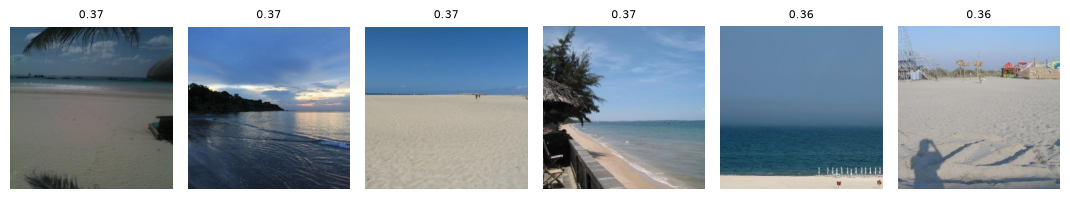

🔎 una habitación con cama


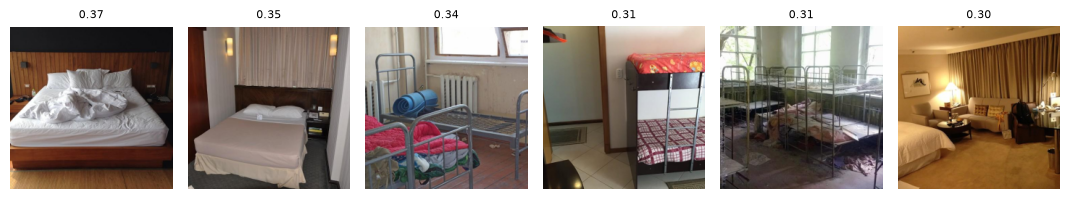

🔎 perro


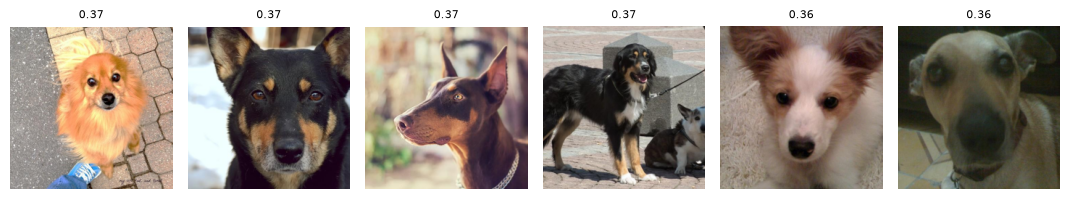

🔎 comida en un plato


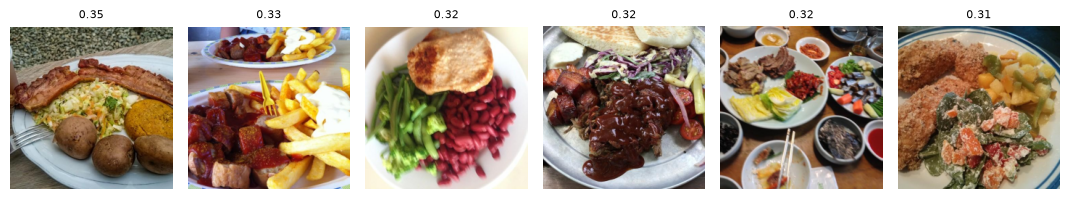

🔎 montañas con nieve


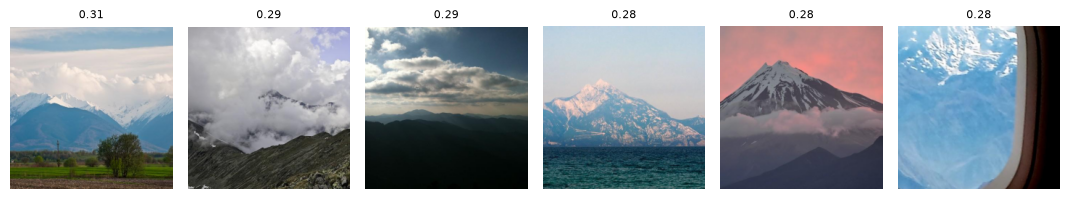

🔎 personas en la calle de una ciudad


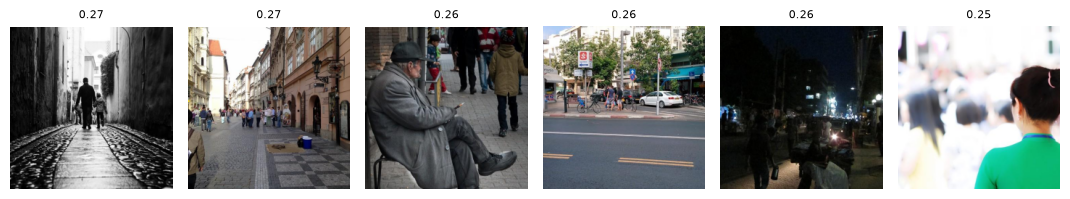

🔎 un coche rojo


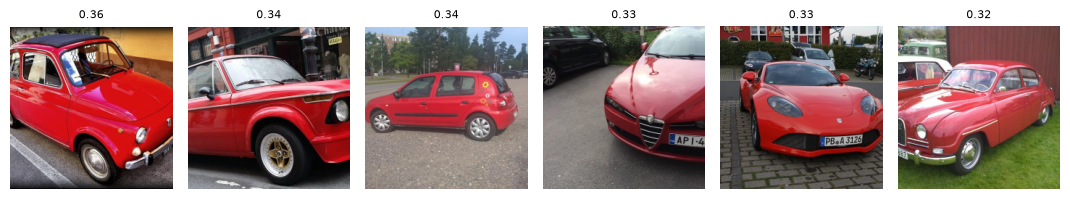

🔎 flores en un jardín


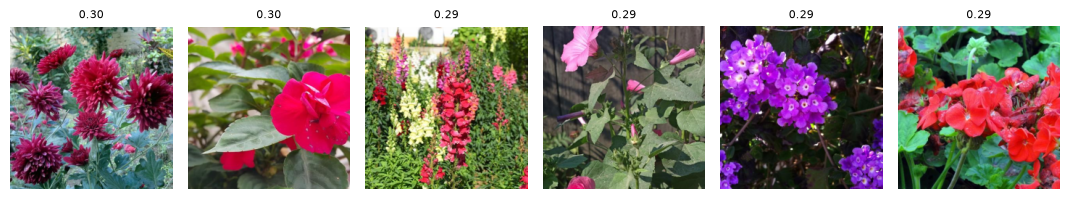

In [14]:
VARIANTE = BEST     # la de mejor R@10; también pueden poner "ligera" o "mediana"
s_txt = sess(OUT / f"{VARIANTE}_texto_fp32.onnx")
VEC = np.load(OUT / f"{VARIANTE}_vectores_xm3600.npy")

def buscar(frase, k=6):
    q = ort_text(s_txt, TOKS[VARIANTE], [frase])[0]
    s = VEC @ q; top = np.argsort(-s)[:k]
    print(f"🔎 {frase}")
    grid([G[i] for i in top], [f"{s[i]:.2f}" for i in top], ncol=k, size=1.8)

PROMPTS = ["playa", "una habitación con cama", "perro", "comida en un plato", "montañas con nieve",
           "personas en la calle de una ciudad", "un coche rojo", "flores en un jardín"]
for p in PROMPTS: buscar(p)

## 9. Agrupar y nombrar

La idea es agrupar primero y nombrar después:

1. Agrupamos las fotos parecidas por sus vectores.
2. Cada grupo recibe sugerencias de nombre: las palabras de `CANDIDATAS` más cercanas a su vector promedio.
3. El usuario confirma o cambia el nombre. **Ese vector promedio queda con nombre**, y las fotos nuevas caen en el grupo más cercano.

Funciona con las dos variantes. Aquí se muestra la de `VARIANTE`, y al final también guardamos los grupos de la otra.

No tenemos etiquetas reales de los grupos, así que los revisamos viendo sus fotos y con la silueta, que mide qué tan separados quedan.

In [15]:
MIN_FOTOS, MIN_COBERTURA = 5, 0.6     # un grupo tiene 5+ fotos; al menos 60 % de las fotos debe quedar en un grupo

def agrupar(V):
    Z = linkage(pdist(V, "cosine"), "average"); sweep = []
    for thr in np.arange(0.30, 0.91, 0.05):
        lab = fcluster(Z, 1 - thr, "distance"); c = Counter(lab)
        if 2 <= len(c) < len(V):
            grandes = [g for g, n in c.items() if n >= MIN_FOTOS]
            sweep.append(dict(umbral=round(float(thr), 2), grupos=len(grandes), cobertura=np.isin(lab, grandes).mean(),
                              mayor_grupo=max(c.values()) / len(V), silueta=silhouette_score(V, lab, metric="cosine")))
    SW = pd.DataFrame(sweep)
    ok = SW[(SW.cobertura >= MIN_COBERTURA) & (SW.mayor_grupo < 0.3)]     # que un grupo no se trague todo
    umbral = float((ok if len(ok) else SW).sort_values("silueta").umbral.iloc[-1])
    lab = fcluster(Z, 1 - umbral, "distance")
    return SW, umbral, lab, [g for g, n in Counter(lab).most_common() if n >= MIN_FOTOS]

SW, UMBRAL, lab, GRUPOS = agrupar(VEC)
SW.to_csv(OUT / "resultados_umbral_grupos.csv", index=False); display(SW)
print(f"umbral {UMBRAL} | {len(GRUPOS)} grupos con {MIN_FOTOS}+ fotos | {sum(np.isin(lab, GRUPOS))} de {len(VEC)} fotos agrupadas")

,umbral,grupos,cobertura,mayor_grupo,silueta
0,0.300,5,0.997,0.991,0.112
1,0.350,11,0.986,0.929,0.001
2,0.400,16,0.973,0.718,-0.017
3,0.450,39,0.961,0.199,0.024
4,0.500,77,0.935,0.101,0.066
5,0.550,131,0.887,0.084,0.079
6,0.600,184,0.775,0.049,0.103
7,0.650,196,0.598,0.038,0.121
8,0.700,156,0.363,0.011,0.143
9,0.750,92,0.174,0.005,0.134


umbral 0.6 | 184 grupos con 5+ fotos | 2790 de 3600 fotos agrupadas


Grupo 440 · 177 fotos · sugerencias: ['flor', 'insecto', 'jardín']


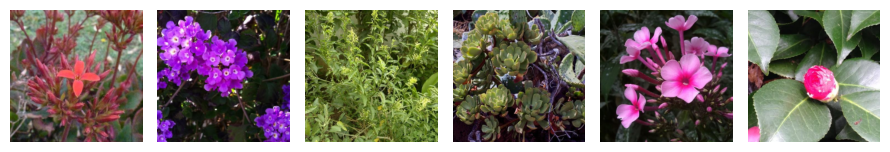

Grupo 432 · 176 fotos · sugerencias: ['comida', 'cocina', 'restaurante']


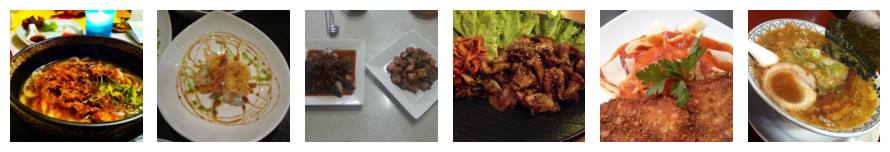

Grupo 264 · 75 fotos · sugerencias: ['bosque', 'árbol', 'carretera']


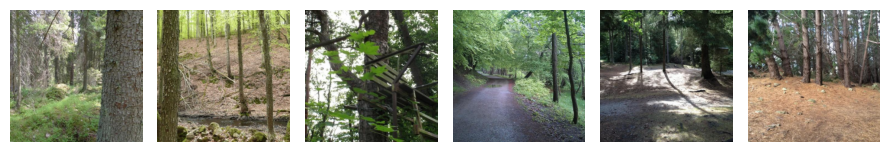

Grupo 436 · 47 fotos · sugerencias: ['perro', 'gato', 'persona']


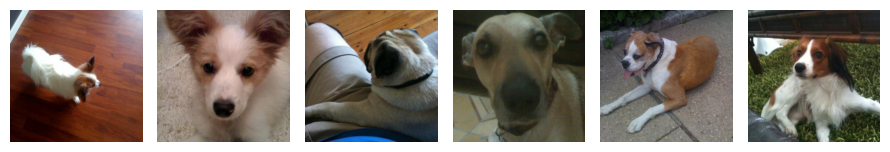

Grupo 439 · 45 fotos · sugerencias: ['verdura', 'fruta', 'comida']


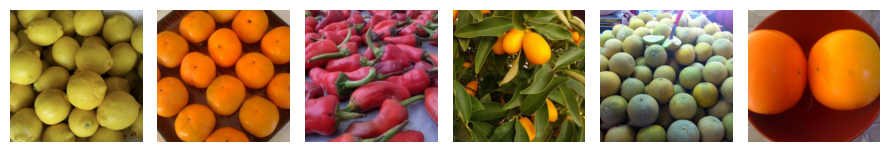

Grupo 445 · 45 fotos · sugerencias: ['insecto', 'persona', 'pez']


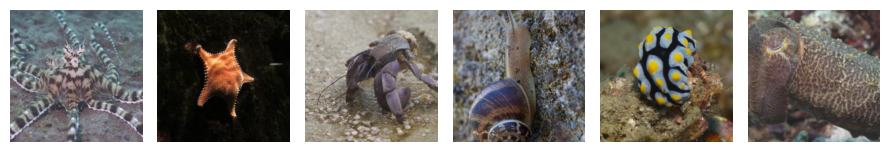

Grupo 179 · 43 fotos · sugerencias: ['coche', 'carretera', 'persona']


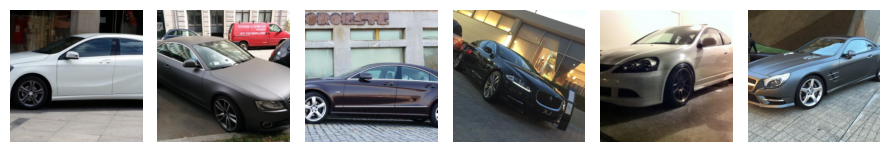

Grupo 426 · 42 fotos · sugerencias: ['bebida', 'comida', 'restaurante']


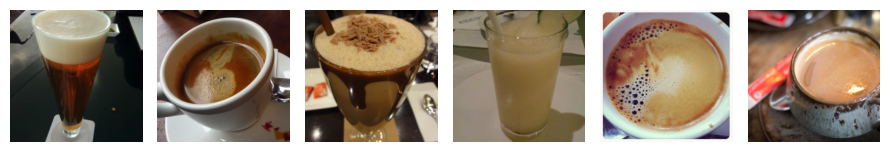

In [16]:
CANDIDATAS = ("playa mar lago río montaña nieve bosque selva desierto campo jardín parque calle ciudad edificio casa iglesia templo puente "
              "habitación cocina baño sala oficina restaurante tienda mercado escuela estadio aeropuerto carretera "
              "comida fruta verdura pastel bebida perro gato pájaro caballo vaca pez insecto flor árbol "
              "coche autobús tren avión barco bicicleta motocicleta persona niño familia grupo de personas deporte "
              "libro computadora teléfono ropa arte estatua noche atardecer").split(" ")
CANDIDATAS = [c for c in CANDIDATAS if c not in ("de", "grupo", "personas")] + ["grupo de personas"]

def nombrar(V, lab, grupos, Vc):
    # Vector promedio de cada grupo y las 3 palabras más cercanas
    centros = {}
    for g in grupos:
        c = V[lab == g].mean(0); centros[int(g)] = c / np.linalg.norm(c)
    return centros, {g: [CANDIDATAS[i] for i in np.argsort(-(Vc @ c))[:3]] for g, c in centros.items()}

CENTROS, SUGERIDOS = nombrar(VEC, lab, GRUPOS, ort_text(s_txt, TOKS[VARIANTE], CANDIDATAS))

for g in GRUPOS[:8]:
    idx = np.where(lab == g)[0]; c = CENTROS[int(g)]; idx = idx[np.argsort(-(VEC[idx] @ c))][:6]
    print(f"Grupo {g} · {(lab == g).sum()} fotos · sugerencias: {SUGERIDOS[int(g)]}")
    grid([G[i] for i in idx], ncol=6, size=1.5, path=OUT / f"fig_grupo_{g}.png")

In [17]:
# El usuario confirma o cambia: {número de grupo: "nombre"}. Lo que no se cambie toma la primera sugerencia.
NOMBRES_USUARIO = {}
NOMBRES = {g: NOMBRES_USUARIO.get(g, s[0]) for g, s in SUGERIDOS.items()}
ids = list(CENTROS); C = np.stack([CENTROS[g] for g in ids])
np.savez(OUT / f"{VARIANTE}_grupos.npz", vectores=C, nombres=np.array([NOMBRES[g] for g in ids]), umbral=UMBRAL)

def asignar(vector):
    # Foto nueva: va al grupo con nombre más cercano, o a "sin grupo"
    s = C @ vector; j = int(s.argmax())
    return (NOMBRES[ids[j]] if s[j] >= UMBRAL else "sin grupo"), float(s[j])

sueltas = np.where(~np.isin(lab, GRUPOS))[0][:5]
for i in sueltas: print(i, asignar(VEC[i]))
display(pd.Series(NOMBRES).value_counts().head(15).to_frame("grupos con ese nombre"))

1 ('habitación', 0.7351863980293274)
9 ('estatua', 0.6715373396873474)
12 ('coche', 0.7302601337432861)
13 ('sin grupo', 0.5070568919181824)
18 ('libro', 0.6993331909179688)


,grupos con ese nombre
persona,19
ciudad,12
coche,11
templo,10
estatua,8
arte,7
montaña,5
edificio,5
tren,5
deporte,5


In [ ]:
# La otra variante también queda con grupos, para poder usarla en el notebook de demo
for otra in VARIANTS:
    if otra == VARIANTE: continue
    V = np.load(OUT / f"{otra}_vectores_xm3600.npy")
    _, u, l, gs = agrupar(V)
    cen, sug = nombrar(V, l, gs, ort_text(sess(OUT / f"{otra}_texto_fp32.onnx"), TOKS[otra], CANDIDATAS))
    np.savez(OUT / f"{otra}_grupos.npz", vectores=np.stack(list(cen.values())), nombres=np.array([sug[g][0] for g in cen]), umbral=u)
    print(f"{otra}: umbral {u} | {len(gs)} grupos | {sum(np.isin(l, gs))} de {len(V)} fotos agrupadas")

## 10. ¿Qué pasa con muchas fotos?
Cada búsqueda compara la frase contra todos los vectores. Simulamos galerías grandes para ver cuánto ocupan y cuánto tardan.

In [18]:
rows = []
for n in [1_000, 10_000, 50_000, 100_000]:
    V = np.random.randn(n, 512).astype(np.float32); V /= np.linalg.norm(V, axis=1, keepdims=True); q = V[0]
    rows.append(dict(fotos=n, MB_float32=n * 2048 / 1e6, MB_float16=n * 1024 / 1e6, ms_busqueda=ms(lambda: np.argsort(-(V @ q))[:20], 10)))
SC = pd.DataFrame(rows); SC.to_csv(OUT / "resultados_escala.csv", index=False); display(SC)

,fotos,MB_float32,MB_float16,ms_busqueda
0,1000,2.048,1.024,0.294
1,10000,20.480,10.240,0.986
2,50000,102.400,51.200,5.640
3,100000,204.800,102.400,9.871


## 11. Demostración
Para abrirla, hay que poner `RUN_DEMO = True`. También está el notebook `AA3_P2_Avance2_Demo.ipynb`, que no entrena nada.

In [19]:
RUN_DEMO = False
import gradio as gr
def demo_fn(frase, k):
    q = ort_text(s_txt, TOKS[VARIANTE], [frase])[0]; s = VEC @ q
    return [(G[i], f"{s[i]:.2f}") for i in np.argsort(-s)[:int(k)]]
with gr.Blocks(title="Buscador de fotos") as demo:
    gr.Markdown("### Buscador de fotos en español")
    t = gr.Textbox(label="¿Qué foto buscas?"); k = gr.Slider(4, 24, 12, step=4, label="Resultados")
    g = gr.Gallery(columns=6, height=500); t.submit(demo_fn, [t, k], g)
if RUN_DEMO: demo.launch()

## 12. Conclusiones

- **El entrenamiento sí ayudó:** en las dos variantes, el modelo propio superó a la línea base. R@10 subió de cerca de 0.29 a 0.61 en la ligera, y de 0.53 a 0.76 en la mediana.
- **Todavía no llega al inglés:** la referencia queda arriba, así que aún hay espacio para mejorar.
- **Ligera o mediana:** la mediana busca mejor, pero pesa cerca de 3 veces más y tarda más. La ligera conviene más para dispositivos sencillos.
- **Dónde falla:** en palabras raras, faltas de ortografía y frases con dos ideas, como "perro en la playa", donde mezcla perros y playas.
- **Agrupar:** los grupos más grandes se ven bien, pero los nombres sugeridos se repiten. El usuario debe poder corregirlos.
- **Agregar fotos no pide reentrenar:** solo se calcula el vector de cada foto nueva.

## 13. Riesgos, siguientes pasos y referencias

### Riesgos y ética
- **Sesgos:** las frases de entrenamiento se tradujeron a máquina, y COCO y YFCC tienen sobre todo escenas occidentales (ver 5.2).
- **Privacidad:** las fotos y sus vectores no salen del dispositivo.
- **Decisiones:** el buscador solo ayuda a encontrar fotos. No debe usarse para decidir nada sobre personas.

### Siguientes pasos
- Probar los ONNX en un dispositivo de gama baja.
- Agregar fotos al índice sin recalcular todo.
- Definir cómo actualizar los vectores cuando cambie el modelo.
